In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

splits = {}

for name in ["train", "validation", "test"]:
    splits[name] = pd.read_csv(root / "data" / f"{name}.csv")

    print(f"\n{name.upper()}")
    print("Размер:", splits[name].shape)
    print("Столбцы:", splits[name].columns.tolist())
    print("Пропуски:", splits[name].isna().sum().to_dict())
    print("Дубликаты:", splits[name].duplicated().sum())

df = pd.concat(
    [data.assign(split=name) for name, data in splits.items()],
    ignore_index=True
)

print("\nОбщее число объектов:", len(df))
print("\nРаспределение классов:")
print(pd.crosstab(df["split"], df["label"]))



TRAIN
Размер: (11089, 2)
Столбцы: ['text', 'label']
Пропуски: {'text': 0, 'label': 0}
Дубликаты: 37

VALIDATION
Размер: (2101, 2)
Столбцы: ['text', 'label']
Пропуски: {'text': 0, 'label': 0}
Дубликаты: 0

TEST
Размер: (2101, 2)
Столбцы: ['text', 'label']
Пропуски: {'text': 0, 'label': 0}
Дубликаты: 0

Общее число объектов: 15291

Распределение классов:
label          0     1
split                 
test        1050  1051
train       6303  4786
validation  1050  1051


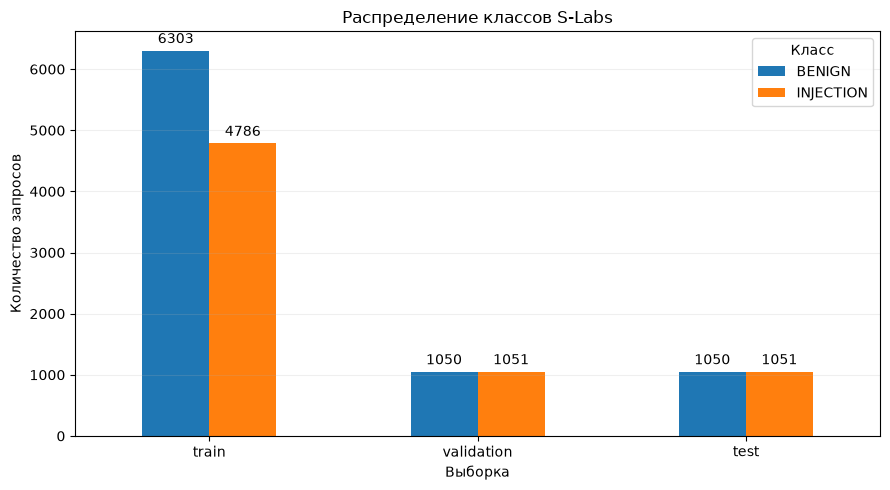

In [3]:
counts = pd.crosstab(df["split"], df["label"])
counts = counts.reindex(index=["train", "validation", "test"], columns=[0, 1], fill_value=0)
counts = counts.rename(columns={0: "BENIGN", 1: "INJECTION"})

ax = counts.plot(kind="bar", figsize=(9, 5), rot=0)

ax.set_title("Распределение классов S-Labs")
ax.set_xlabel("Выборка")
ax.set_ylabel("Количество запросов")
ax.legend(title="Класс")
ax.grid(axis="y", alpha=0.2)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()
